In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit

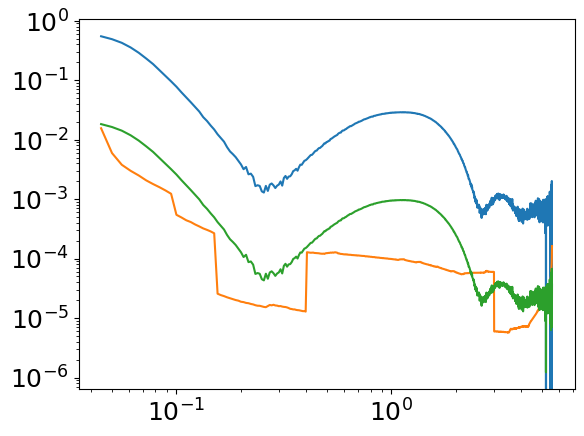

In [3]:
sample = "BII_S9" # "BII_S9_15mM_LV4_PBS_FVII"
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

Ierr_op = BM29.Poisson_error_focus_minimum_highq(q, Ierr)
plt.loglog(q, I)
plt.loglog(q, Ierr_op)
plt.loglog(q, BM29.op_error_classic(q, I))

Fit results with 1σ uncertainties:

sigma_head_fit = 0.33527 ± 0.018606
sigma_tail_fit = 0.6 ± 0.03482
rho_head_fit = 1 ± 0.037364
eps_head_fit = 1.8828 ± 0.017743
scale_fit = 0.48 ± 0.029559
chi2 = 17742


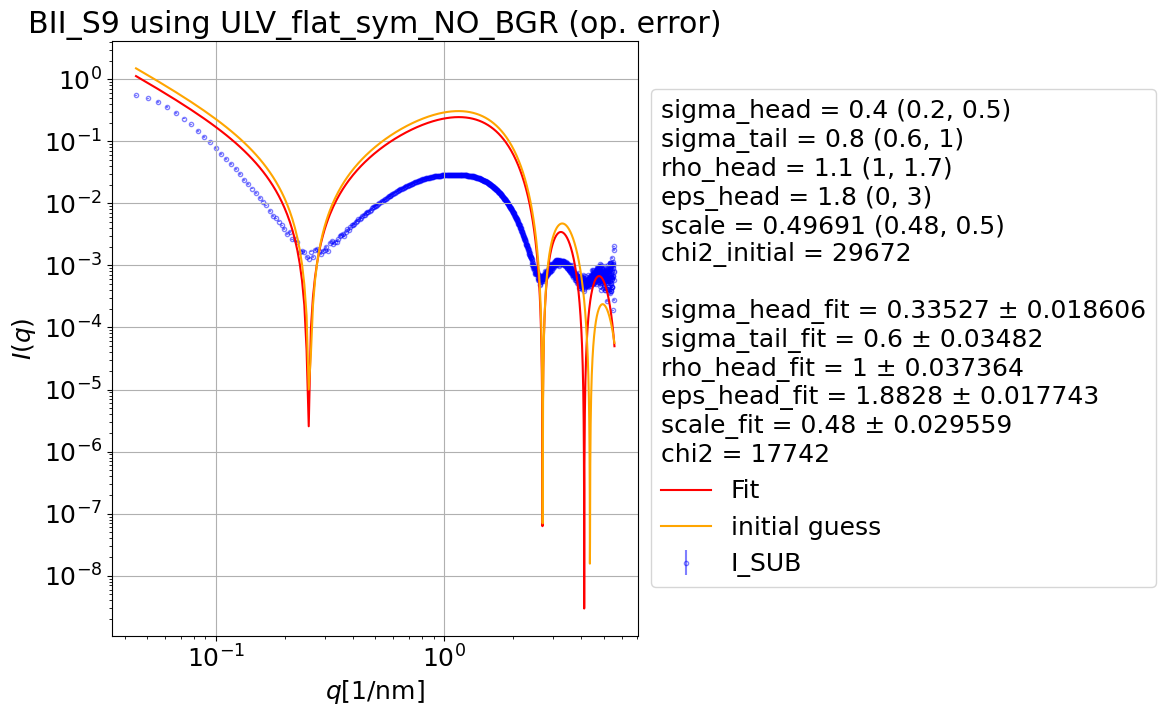

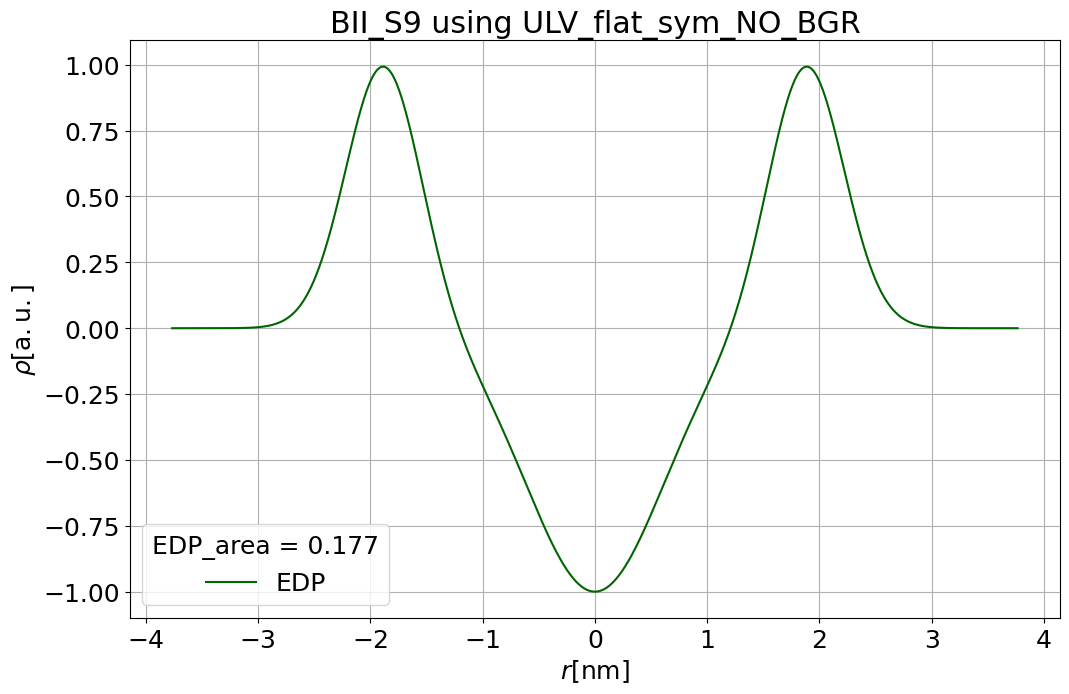

In [3]:
fit_function = fit.ULV_flat_sym_NO_BGR
plt.close("all")

param_set = "flat_sym_NO_BGR"

q     = q
I     = I
I_err = np.abs(I / 30) #Ierr

# ========================== Parameters ==========================
R       = 0
sigma_R = 0

sigma_head   = 0.4
sigma_tail = 0.8
rho_head   = 1.1
eps_head = 1.8

scale = 0.49691 

# ========================== Setting Bounds ==============================

p0           = [sigma_head, sigma_tail, rho_head,   eps_head,    scale]     
lower_bounds = [       0.2,        0.6,        1,          0,     0.48]
upper_bounds = [       0.5,          1,      1.7,          3,      0.5]


#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = fit.param_names.get(param_set)

perr = np.sqrt(np.diag(pcov))
for name, value in zip(param_names, popt):
    globals()[name] = value
chi2, info_text = fit.info(q, I, I_err, param_names, p0, popt, perr, fit_function)

residuals = I - fit_function(q, *p0)
initial_chi2 = np.sum((residuals / I_err)**2) / (len(I) - len(p0) - 1)
names2 = [name[:-4] for name in param_names]
info_text2 = "\n".join(f"{name} = {val:.5g} ({lower_bounds[i]}, {upper_bounds[i]})" for name, val, i in zip(names2, p0, range(len(p0))))
info_text2 += f"\nchi2_initial = {initial_chi2:.5g}\n \n"
info_text_print = info_text2 + info_text
# with open(target_folder/"info_texts_LV4.txt", "a", encoding="utf-8") as k:
#     k.write(f"\n\n{sample} f={fac} using {fit_function.__name__}_q0p8\n" + info_text_print + "\n###########################################\n")
#=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), 1000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
# plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2_fit, c3_fit, c4_fit), color='black', label='pow law bgr')
# plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{sample} using {fit_function.__name__} (op. error)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{fit_function.__name__}_op_error.png", bbox_inches='tight', pad_inches=0.05)
plt.show()

fig=fit.EDP_plot(0, sigma_head_fit, sigma_head_fit, sigma_tail_fit, rho_head_fit, rho_head_fit, eps_head_fit, eps_head_fit, info_text, 
             f'{sample} using {fit_function.__name__}')
# # fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error.png", dpi=400, bbox_inches='tight', pad_inches=0.05)
# pow_law_reality_check(c2_fit, c3_fit, c4_fit)
# type(popt)


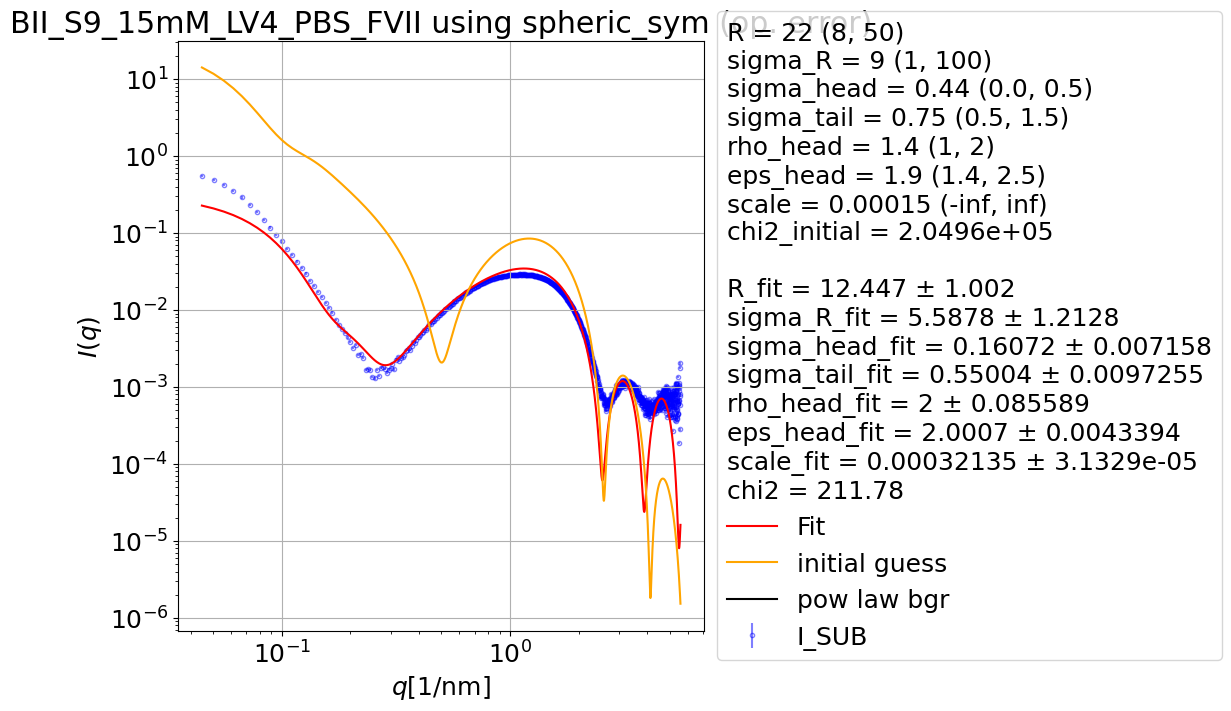

In [ ]:
# SPHERIC SYM NO BGR
"""
Iteration 136900, current chi2 = 371.4
Current params:  [19.03271425  4.29641427  0.30977882  0.57037533  1.5595231   1.84166663 0.05611819]
"""

fit_function = lambda q, R,    sigma_R, sigma_head, sigma_tail, rho_head,  eps_head,    scale: fit.ULV_spheric_sym(q, R,    sigma_R, sigma_head, sigma_tail, rho_head,  eps_head,    scale,      0, 0, 0)
#fit_function = fit.ULV_spheric_sym_num
plt.close("all")

param_set = "spheric_sym"

q     = q
I     = I
I_err = np.abs(I * 1/30) # Ierr

# ========================== Parameters ==========================
R       = 22
sigma_R = 9

sigma_head =0.44# 0.3929 
sigma_tail = 0.75
rho_head = 1.4 #1.2256 
eps_head = 1.9
scale = 0.00015
c2 = 0 
c3 = 0
c4 = 0

# ========================== Setting Bounds ==============================
p0           = [   R,    sigma_R, sigma_head, sigma_tail, rho_head,  eps_head,    scale] #,      c2,      c3,      c4]
lower_bounds = [   8,          1,        0.0,        0.5,        1,       1.4,  -np.inf] #,       0,       0,       0]
upper_bounds = [  50,        100,        0.5,        1.5,        2,       2.5,  +np.inf] #,   1e-10,   1e-10,   1e-10]

#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = ["R_fit", "sigma_R_fit", "sigma_head_fit", "sigma_tail_fit", 
               "rho_head_fit", "eps_head_fit", "scale_fit"]

perr = np.sqrt(np.diag(pcov))
for name, value in zip(param_names, popt):
    globals()[name] = value
chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)

#=========================== Plot ===========================================
q_fit = np.linspace(min(q), max(q), 1000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, R, sigma_R, sigma_head, sigma_tail, rho_head,   eps_head,   scale), color='orange', label='initial guess')
plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, 0, 0, 0), color='black', label='pow law bgr')
# plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using spheric_sym (op. error)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{fit_function.__name__}_operative_error.png",dpi=400, bbox_inches='tight', pad_inches=0.05)
plt.show()
# fig = fit.EDP_plot(R_fit, sigma_head, sigma_head, sigma_tail, rho_head, rho_head, eps_head, eps_head, info_text_print, 
#              f'{sample} using {fit_function.__name__}')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

# pow_law_reality_check(c2_fit, c3_fit, c4_fit)


In [20]:
# SPHERIC SYM + c4
fit_function = lambda q, R,    sigma_R, sigma_head, sigma_tail, rho_head,  eps_head,    scale, c4: fit.ULV_spheric_sym(q, R,    sigma_R, sigma_head, sigma_tail, rho_head,  eps_head,    scale,      0, 0, c4)
#fit_function = fit.ULV_spheric_sym_num
plt.close("all")

param_set = "spheric_sym"

q     = q
I     = I
I_err = np.abs(I * 1/30) # Ierr

# ========================== Parameters ==========================
R       = 25
sigma_R = 10

sigma_head =0.34# 0.3929 
sigma_tail = 0.9
rho_head = 1.5 #1.2256 
eps_head = 1.7
scale = 0.00015
c2 = 0 
c3 = 0
c4 = 0.00027

# ========================== Setting Bounds ==============================
p0           = [   R,    sigma_R, sigma_head, sigma_tail, rho_head,  eps_head,    scale,      c4] #,      c2,      c3,      c4]
lower_bounds = [   8,          1,        0.0,        0.5,        1,       1.4,  -np.inf, -np.inf] #,       0,       0,       0]
upper_bounds = [  50,        100,        0.5,        1.5,        2,       2.5,  +np.inf, +np.inf] #,   1e-10,   1e-10,   1e-10]


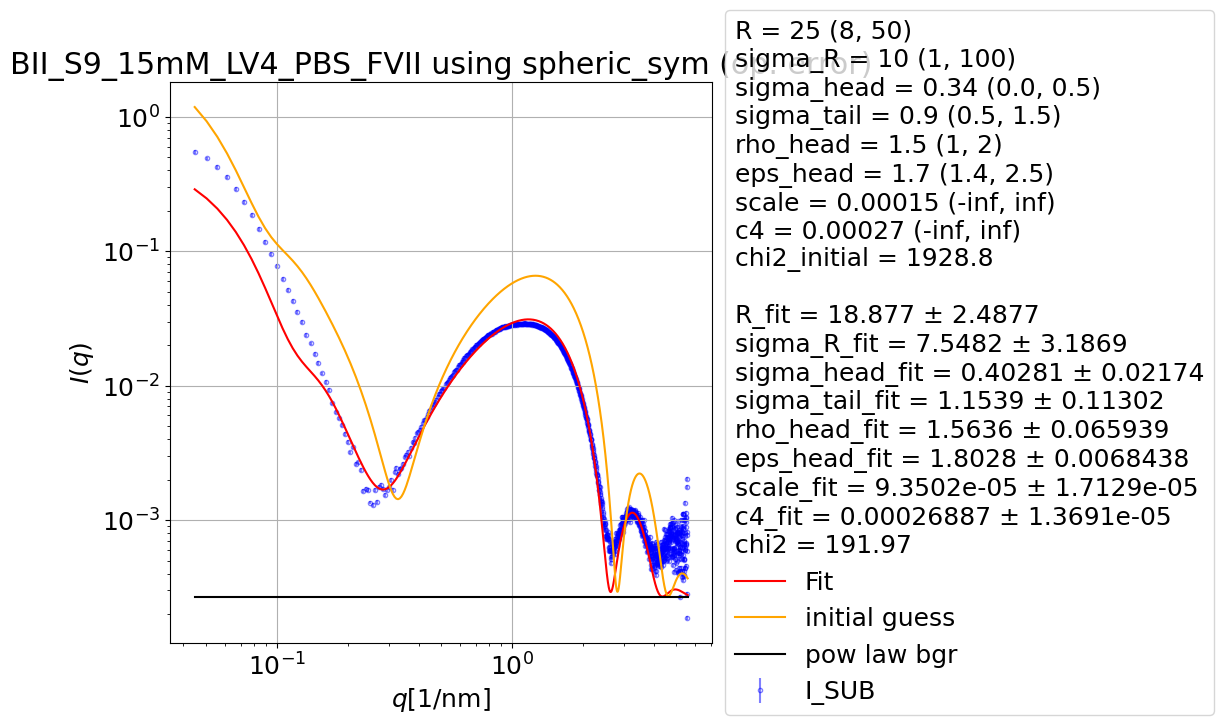

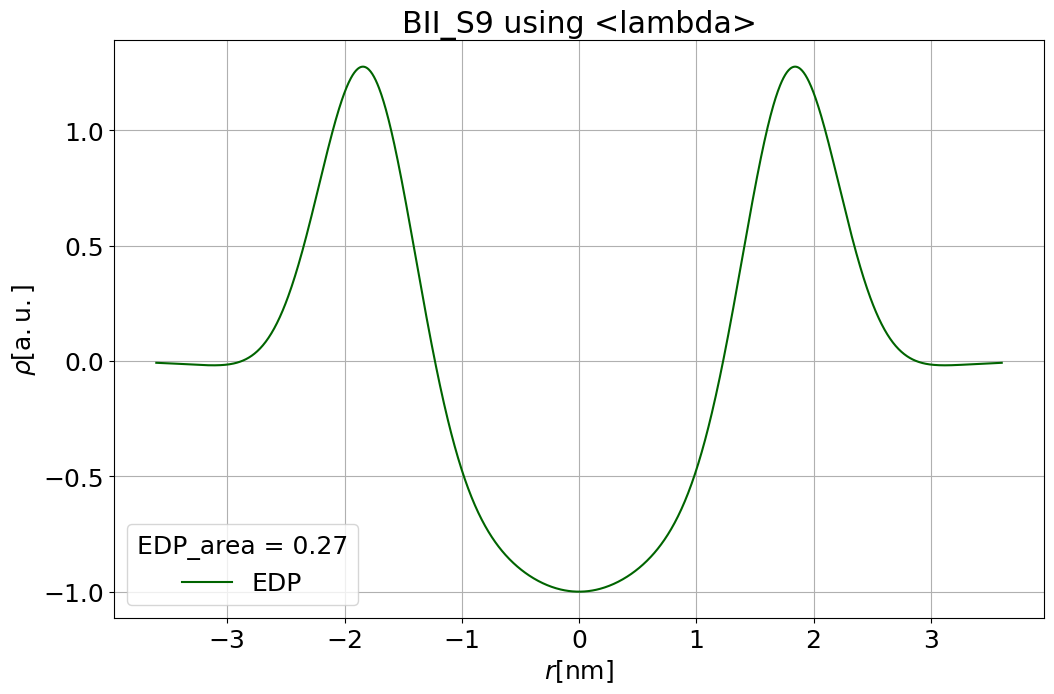

In [21]:
#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = ["R_fit", "sigma_R_fit", "sigma_head_fit", "sigma_tail_fit", 
               "rho_head_fit", "eps_head_fit", "scale_fit", "c4_fit"]

perr = np.sqrt(np.diag(pcov))
for name, value in zip(param_names, popt):
    globals()[name] = value
chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)

#=========================== Plot ===========================================
q_fit = np.linspace(min(q), max(q), 1000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, R, sigma_R, sigma_head, sigma_tail, rho_head,   eps_head,   scale, c4), color='orange', label='initial guess')
plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, 0, 0, c4_fit), color='black', label='pow law bgr')
# plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using spheric_sym (op. error)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{fit_function.__name__}_operative_error.png",dpi=400, bbox_inches='tight', pad_inches=0.05)
plt.show()
fig = fit.EDP_plot(R_fit, sigma_head_fit, sigma_head_fit, sigma_tail_fit, rho_head_fit, rho_head_fit, eps_head_fit, eps_head_fit, info_text_print, 
             f'{sample} using {fit_function.__name__}')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

# pow_law_reality_check(c2_fit, c3_fit, c4_fit)


In [ ]:
# FLAT ASYM NO BGR
fit_function = lambda q, sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2,   eps_head,       scale: fit.ULV_flat_asym(q, sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2,   eps_head,       scale,      0, 0, 0)
plt.close("all")

param_set = "flat_asym"

q     = q
I     = I
I_err = np.abs(I / 30) #Ierr

# ========================== Parameters ==========================
R       = 0
sigma_R = 0

sigma_h1 = 0.4
sigma_h2 = 0.2
sigma_tail = 0.75 
rho_h1 = 1
rho_h2 = 2
eps_head = 1.8305 
scale = 0.037848 

c2    = 0
c3    = 0
c4    = 0
# ========================== Setting Bounds ==============================

p0           = [sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2,   eps_head,       scale] #,      c2,      c3,      c4]
lower_bounds = [    0.10,     0.10,        0.5,    0.0,    0.0,        1.7,     -np.inf] #,       0,       0,       0]
upper_bounds = [     0.6,      0.6,        0.9,    4.0,    4.0,          2,     +np.inf] #,   1e-10,   1e-10,   1e-10]

NameError: name 'plt' is not defined

In [2]:
#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=20000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = fit.param_names.get(param_set)

perr = np.sqrt(np.diag(pcov))
for name, value in zip(param_names, popt):
    globals()[name] = value
chi2, info_text = fit.info(q, I, I_err, param_names, p0, popt, perr, fit_function)

residuals = I - fit_function(q, *p0)
initial_chi2 = np.sum((residuals / I_err)**2) / (len(I) - len(p0) - 1)
names2 = [name[:-4] for name in param_names]
info_text2 = "\n".join(f"{name} = {val:.5g} ({lower_bounds[i]}, {upper_bounds[i]})" for name, val, i in zip(names2, p0, range(len(p0))))
info_text2 += f"\nchi2_initial = {initial_chi2:.5g}\n \n"

info_text_print = info_text2 + info_text
#=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), 10000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
# plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2_fit, c3_fit, c4_fit), color='black', label='bgr')
# plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using flat_asym (op. error)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{fit_function.__name__}_operative_error_2.png",dpi=400, bbox_inches='tight', pad_inches=0.05)
plt.show()

# =========== EDP =====================================================================================
fig = fit.EDP_plot(0, sigma_h1_fit, sigma_h2_fit, sigma_tail_fit, rho_h1_fit, rho_h2_fit, eps_head_fit, eps_head_fit, info_text, 
             f'{sample} using {fit_function.__name__}')
# # fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error_2.png", dpi=400, bbox_inches='tight', pad_inches=0.05)
# fig = fit.EDP_plot(0, sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2, eps_head, eps_head, info_text, 
#                    f'{sample} using {fit_function.__name__} (initial guess)')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_INITIAL GUESS_op_error_2.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

# pow_law_reality_check(c2_fit, c3_fit, c4_fit)

NameError: name 'curve_fit' is not defined

In [ ]:
# FLAT ASYM + c4
fit_function = lambda q, sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2,   eps_head,       scale, c4: fit.ULV_flat_asym(q, sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2,   eps_head,       scale,      0, 0, c4)
plt.close("all")

param_set = "flat_asym"

q     = q
I     = I
I_err = np.abs(I / 30) #Ierr

# ========================== Parameters ==========================
R       = 0
sigma_R = 0

sigma_h1 = 0.4
sigma_h2 = 0.2
sigma_tail = 0.75 
rho_h1 = 1
rho_h2 = 2
eps_head = 1.8305 
scale = 0.037848 

c2    = 0
c3    = 0
c4    = 0.0001
# ========================== Setting Bounds ==============================

p0           = [sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2,   eps_head,       scale,      c4] #,      c2,      c3,      c4]
lower_bounds = [    0.10,     0.10,        0.5,    0.0,    0.0,        1.7,     -np.inf,  0.0001] #,       0,       0,       0]
upper_bounds = [     0.6,      0.6,        0.9,    4.0,    4.0,          2,     +np.inf, +np.inf] #,   1e-10,   1e-10,   1e-10]

Fit results with 1σ uncertainties:

sigma_h1_fit = 0.55508 ± 0.013561
sigma_h2_fit = 0.21074 ± 0.066026
sigma_tail_fit = 0.9 ± 0.10416
rho_h1_fit = 0.82012 ± 0.092915
rho_h2_fit = 2.6274 ± 0.58572
eps_head_fit = 1.8316 ± 0.025013
scale_fit = 0.041254 ± 0.0019943
c4_fit = 0.0001 ± 8.9936e-05
chi2 = 148.09


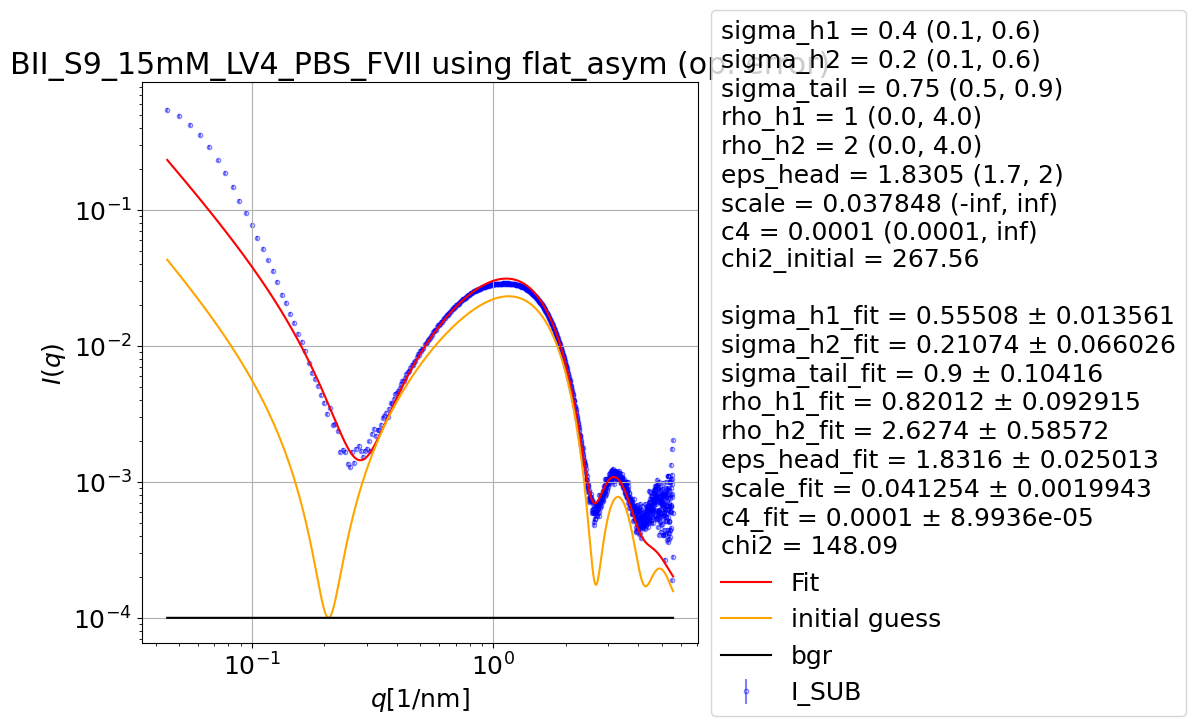

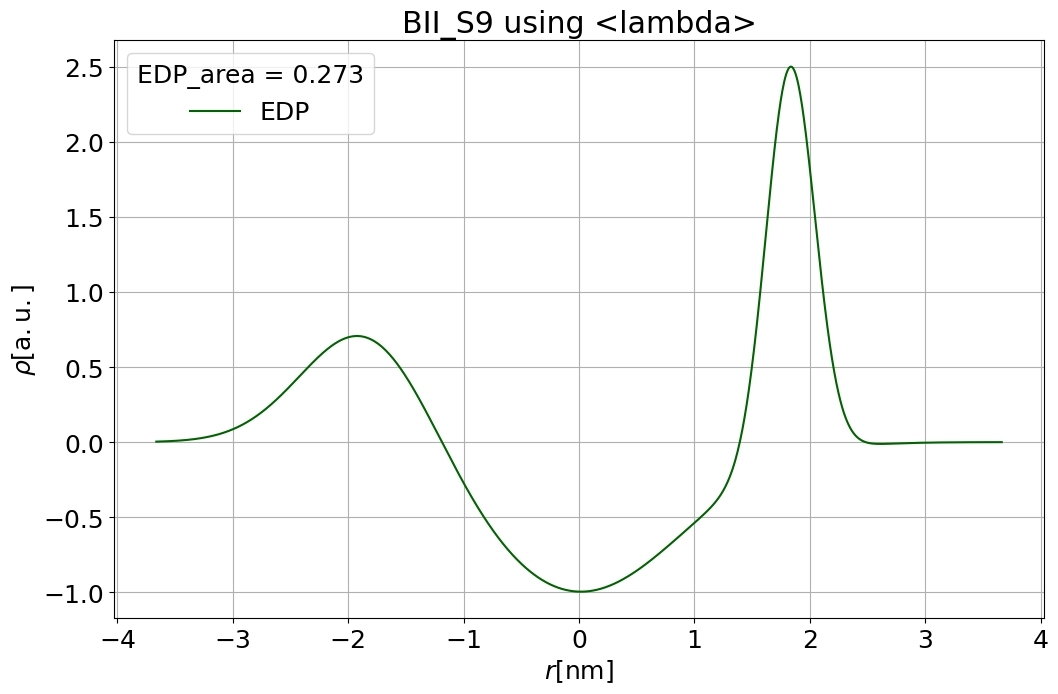

In [39]:
#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=20000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = ["sigma_h1_fit", "sigma_h2_fit", "sigma_tail_fit", "rho_h1_fit", "rho_h2_fit", 
                     "eps_head_fit", "scale_fit", "c4_fit"]

perr = np.sqrt(np.diag(pcov))
for name, value in zip(param_names, popt):
    globals()[name] = value
chi2, info_text = fit.info(q, I, I_err, param_names, p0, popt, perr, fit_function)

residuals = I - fit_function(q, *p0)
initial_chi2 = np.sum((residuals / I_err)**2) / (len(I) - len(p0) - 1)
names2 = [name[:-4] for name in param_names]
info_text2 = "\n".join(f"{name} = {val:.5g} ({lower_bounds[i]}, {upper_bounds[i]})" for name, val, i in zip(names2, p0, range(len(p0))))
info_text2 += f"\nchi2_initial = {initial_chi2:.5g}\n \n"

info_text_print = info_text2 + info_text
#=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), 10000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, 0, 0, c4_fit), color='black', label='bgr')
# plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using flat_asym (op. error)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{fit_function.__name__}_operative_error_2.png",dpi=400, bbox_inches='tight', pad_inches=0.05)
plt.show()

# =========== EDP =====================================================================================
fig = fit.EDP_plot(0, sigma_h1_fit, sigma_h2_fit, sigma_tail_fit, rho_h1_fit, rho_h2_fit, eps_head_fit, eps_head_fit, info_text, 
             f'{sample} using {fit_function.__name__}')
# # fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error_2.png", dpi=400, bbox_inches='tight', pad_inches=0.05)
# fig = fit.EDP_plot(0, sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2, eps_head, eps_head, info_text, 
#                    f'{sample} using {fit_function.__name__} (initial guess)')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_INITIAL GUESS_op_error_2.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

# pow_law_reality_check(c2_fit, c3_fit, c4_fit)

In [17]:
# SPHERIC ASYM
fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale: fit.ULV_spheric_asym(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, 0)

"""
Iteration 48300, current chi2 = 332.2
Current params:  [13.84263741  7.45905129  1.01586004  1.71244435  0.49757307  0.59267887 0.52259504  1.57056397  0.12634116]
"""

param_set = "spheric_asym"
q     = q
I     = I
I_err_Poisson = Ierr
I_err_op = np.abs(I * 1/30) 
mask = (q <= 0.1) & (q >= 4.1)
I_err_op[mask] = np.abs(I[mask] * 1/15) 
I_err_Poisson[mask] = I_err_Poisson[mask] * 2

# q_mask = q >= 0.1
# I_err[q_mask] = np.abs(I[q_mask] / 15)

# ========================== Parameters ==========================
R = 18
sigma_R = 7
rho_h1 = 2.7
rho_h2 = 1.8
sigma_h1 = 0.2
sigma_h2 = 0.3
sigma_c = 0.75
z_h = 1.75
scale = 0.00013965

# ========================== Setting Bounds ==============================
p0           = [   R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale] #,      c2,      c3,      c4]
lower_bounds = [   9,          2,        1,        1,        0.13,      0.13,      0.5,    1.5, -np.inf] #,       0,       0, -np.inf]
upper_bounds = [  25,          8,      3.5,      3.5,         0.8,       0.8,      1.2,      2, +np.inf] #,       4,     0.5, +np.inf]
p0 = [13.84263741,  7.45905129,  1.01586004,  1.71244435, 0.49757307, 0.59267887, 0.52259504,  1.57056397,  0.12634116]
p0 = [17, 3, 1.225, 2.5, 0.6374, 0.1734, 1.152, 1.787, 0.0001424]


[21.87, 4.563, 1, 3.482, 0.7038, 0.13, 1.013, 1.763, 9.108e-05]
R = 17 (9, 25)
sigma_R = 3 (2, 8)
rho_h1 = 1.225 (1, 3.5)
rho_h2 = 2.5 (1, 3.5)
sigma_h1 = 0.6374 (0.13, 0.8)
sigma_h2 = 0.1734 (0.13, 0.8)
sigma_c = 1.152 (0.5, 1.2)
z_h = 1.787 (1.5, 2)
scale = 0.0001424 (-inf, inf)
chi2_initial = 683.5
 
R_fit = 21.868 ± 0.18757
sigma_R_fit = 4.5628 ± 0.14172
rho_h1_fit = 1 ± 0.030072
rho_h2_fit = 3.4822 ± 0.6041
sigma_h1_fit = 0.70383 ± 0.0069285
sigma_h2_fit = 0.13001 ± 0.027351
sigma_c_fit = 1.0128 ± 0.041075
z_h_fit = 1.7627 ± 0.0046049
scale_fit = 9.1078e-05 ± 1.9048e-06
chi2 = 34.082


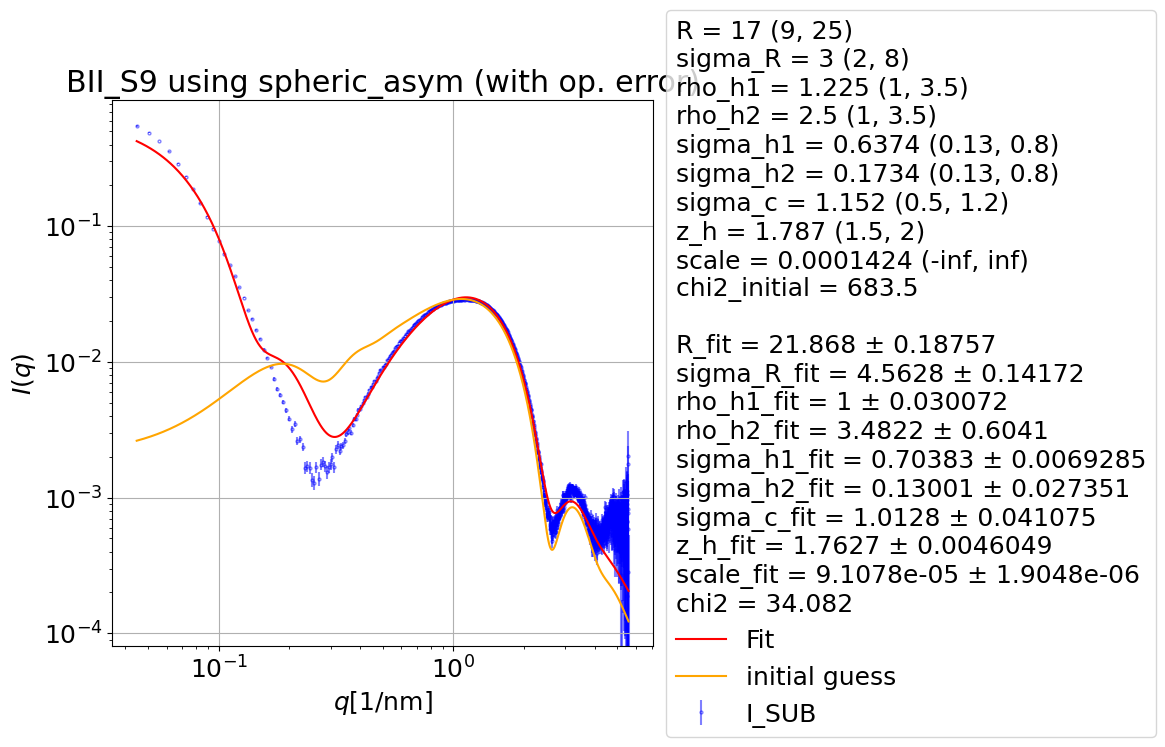

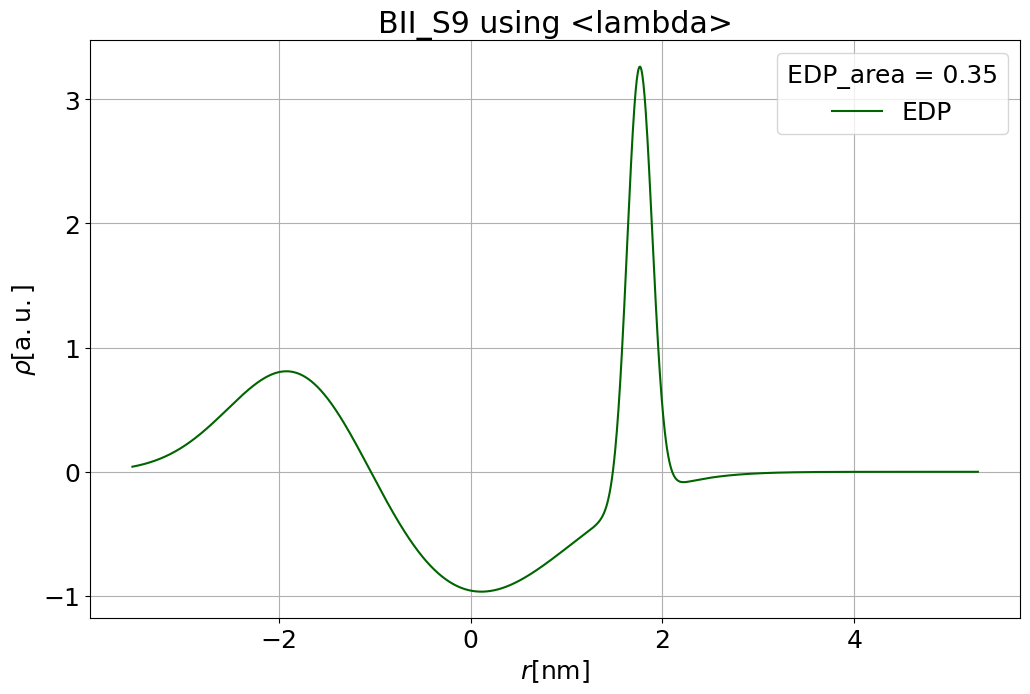

In [18]:
#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err_Poisson, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = fit.param_names.get(param_set)

perr = np.sqrt(np.diag(pcov))
fit_lib_entry = "["
for name, value in zip(param_names, popt):
    globals()[name] = value
    fit_lib_entry += f"{value:.4g}, "
fit_lib_entry = fit_lib_entry[:-2]
fit_lib_entry += "]"
print(fit_lib_entry)

chi2, info_text_print = fit.all_info(q, I, I_err_Poisson, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
print(info_text_print)

#=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), 10000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err_Poisson, marker="o", markersize=2,markeredgewidth=1,ecolor="Blue", markeredgecolor='Blue', markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{sample} using spheric_asym (with op. error)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{fit_function.__name__}_op_error2.png",dpi=400, bbox_inches='tight', pad_inches=0.05)
plt.show()

fig=fit.EDP_plot(R_fit, sigma_h1_fit, sigma_h2_fit, sigma_c_fit, rho_h1_fit, rho_h2_fit, z_h_fit, z_h_fit, info_text_print, 
             f'{sample} using {fit_function.__name__}')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error2.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

In [8]:
# spheric asym good fits
R_fit = 16.672 ± 0.82179
sigma_R_fit = 3.1798 ± 0.46368
rho_h1_fit = 3.7643 ± 0.13501
rho_h2_fit = 0.72117 ± 0.028021
sigma_h1_fit = 0.1647 ± 0.0084499
sigma_h2_fit = 0.55318 ± 0.012865
sigma_c_fit = 0.88177 ± 0.030086
z_h_fit = 1.8378 ± 0.009789
scale_fit = 0.00013965 ± 1.3577e-05
chi2 = 140.8

SyntaxError: invalid character '±' (U+00B1) (2438376538.py, line 2)

In [3]:
# ellipsoidal sym
fit_function = lambda q,  R,  sigma_R,     eps, sigma_eps,  rho_h, sigma_h,    sigma_c,      z_h,    scale: fit.ULV_ellipsoid(q, R,  sigma_R,     eps, sigma_eps,  rho_h, sigma_h,    sigma_c,      z_h,    scale,   0, 0, 0)
plt.close("all")

param_set = "ULV_ellipsoid"

q     = q
I     = I 
I_err = Ierr # np.maximum(I, 0) / 30
thinning = 4
q_thinned = q[::thinning]
I_thinned = I[::thinning]
I_err_thinned = I_err[::thinning]

# ========================== Parameters ==========================
R = 20
sigma_R = 5
eps = 1
sigma_eps = 0.2
rho_h = 1.48
sigma_h = 0.3
sigma_c = 0.77
z_h = 1.8
scale = 1e-7
c2 = 0
c3 = 0
c4 = 0.007

# ========================== Setting Bounds ==============================
# popt = [        R_fit,  sigma_R_fit,     eps_fit, sigma_eps_fit,  rho_h_fit, sigma_h_fit,  sigma_c_fit,      z_h_fit,    scale_fit,   c2_fit,   c3_fit,       c4_fit]
p0           = [        R,  sigma_R,     eps, sigma_eps,  rho_h, sigma_h,    sigma_c,      z_h,    scale] # ,   c2,   c3,       c4]
lower_bounds = [        9,        2,     0.8,         0,      0,     0.2,        0.5,      1.5,  -np.inf] # ,    0,    0,  -np.inf]
upper_bounds = [       25,        9,     1.5,       0.7,     10,     0.5,          1,        2,  +np.inf] # ,  0.2,  0.5,  +np.inf]
p0 = [16.13, 4.991, 1, 0.4378, 2.8, 0.1209, 0.5588, 1.876, 3.666e-07]


Computing I(q): 100%|██████████████████████| 1000/1000 [00:03<00:00, 252.21it/s]


NameError: name 'info_text_print' is not defined

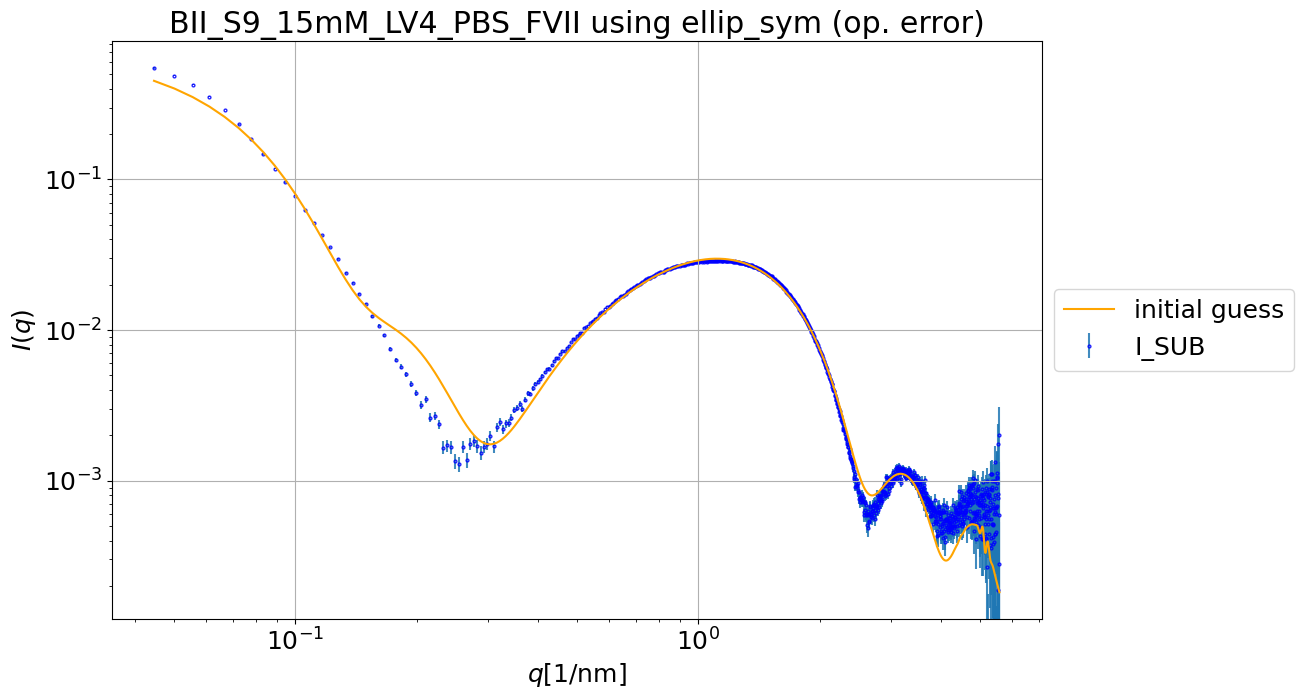

In [4]:
#======================== Fit ===========================================
# popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=1000, p0=p0, bounds = (lower_bounds, upper_bounds))

# param_names = fit.param_names.get(param_set)

# perr = np.sqrt(np.diag(pcov))
# for name, value in zip(param_names, popt):
#     globals()[name] = value
# chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
# #=========================== Plot ===========================================

q_fit = q
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=2,markeredgewidth=1,markeredgecolor='Blue', markerfacecolor='None', alpha=0.85, ls="None", label='I_SUB', zorder=1)
# plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using ellip_sym (op. error)')
plt.grid(True)
plt.legend()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)

plt.tight_layout()
# plt.savefig(target_folder / f"LV4_{fit_function.__name__}_Jan31.png", bbox_inches='tight', pad_inches=0.05)
plt.show()
info_text="_"
#==================== EDP Plot ==================================================
# fig=fit.EDP_plot(R, sigma_h_fit, sigma_h_fit, sigma_c_fit, rho_h_fit, rho_h_fit, z_h_fit, z_h_fit, info_text, 
#              f'{sample} fac={fac} using {fit_function.__name__}')
fig=fit.EDP_plot(R, sigma_h, sigma_h, sigma_c, rho_h, rho_h, z_h, z_h, info_text, 
             f'{BM29.sample_dict[sample]} using ellip_sym (initial guess)')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_FINAL.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

# pow_law_reality_check(c2_fit, c3_fit, c4_fit)


In [ ]:
# ULV_ellipsoid_asym
fit_function = lambda q,  R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale: fit.ULV_ellipsoid_asym(q, R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale,   0, 0, 0)
plt.close("all")

param_set = "ULV_ellipsoid_asym"

q     = q
I     = I 
I_err = Ierr # np.maximum(I, 0) / 30
I_err_op = np.maximum(I, 0.01) / 30
I_err_op20 = np.maximum(I, 0.01) / 20

thinning = 1
q_thinned = q[::thinning]
I_thinned = I[::thinning]
I_err_thinned = I_err[::thinning]

# ========================== Parameters ==========================
p0 = [16.13, 4.991, 1, 0.4378, 2.8, 0.1209, 0.5588, 1.876, 3.666e-07]

R       = 16.13
sigma_R = 4.99
eps  = 1
sigma_eps = 0.437

rho_h1   = 2.8
rho_h2   = 2.5
sigma_h1 = 0.13
sigma_h2 = 0.12
sigma_c = 0.558
z_h = 1.8468

scale = 3.66e-7
c2    = 0.002
c3    = 0.010452
c4    = 0


# ========================== Setting Bounds ==============================
# popt = [        R_fit,  sigma_R_fit,     eps_fit, sigma_eps_fit,  rho_h1_fit, rho_h2_fit,   sigma_h1_fit, sigma_h2_fit,  sigma_c_fit,      z_h_fit,    scale_fit,   c2_fit,   c3_fit,       c4_fit]
p0           = [        R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale] # ,   c2,   c3,       c4]
p0 = [11.41, 4.764, 0.907, 0.5274, 2.9, 2.9, 0.1251, 0.1098, 0.5729, 1.86, 7.683e-07]
p0 = [11.65, 4.716, 0.8948, 0.5089, 2.9, 2.346, 0.1286, 0.1426, 0.5977, 1.861, 7.249e-07]

Computing I(q): 100%|███████████████████████| 1000/1000 [00:12<00:00, 77.18it/s]


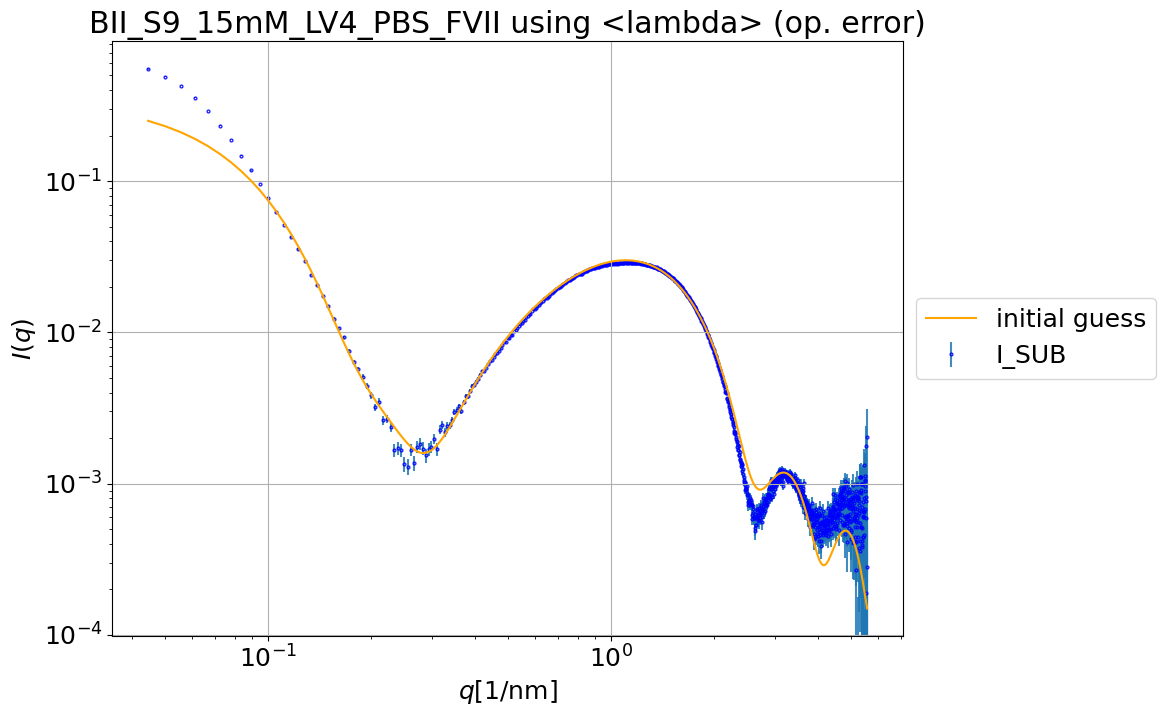

In [6]:
lower_bounds = [        9,        2,     0.8,         0,       0,      0,        0.2,      0.2,      0.5,      1.5,  -np.inf] # ,    0,    0,  -np.inf]
upper_bounds = [       25,        9,     1.5,       0.7,      10,     10,        0.5,      0.5,        1,        2,  +np.inf] # ,  0.2,  0.5,  +np.inf]
#======================== Fit ===========================================
# residuals = I - fit_function(q, *popt)
# chi2 = np.sum((residuals / I_err)**2) / (len(I) - len(p0) - 1)
# print(chi2)
# residuals = I - fit_function(q, *popt)
# chi2 = np.sum((residuals / I_err_op)**2) / (len(I) - len(p0) - 1)
# print("chi2 op. err. /30", chi2)
# residuals = I - fit_function(q, *popt)
# chi2 = np.sum((residuals / I_err_op20)**2) / (len(I) - len(p0) - 1)
# print("chi2 op. err. /20", chi2)
# popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=1000, p0=p0, bounds = (lower_bounds, upper_bounds))

# param_names = fit.param_names.get(param_set)

# perr = np.sqrt(np.diag(pcov))
# for name, value in zip(param_names, popt):
#     globals()[name] = value
# chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
# #=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), len(q_thinned))
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=2,markeredgewidth=1,markeredgecolor='Blue', markerfacecolor='None', alpha=0.85, ls="None", label='I_SUB', zorder=1)
# plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
# plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2_fit, c3_fit, c4_fit), color='black', label='pow law bgr')
# plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using {fit_function.__name__} (op. error)')
plt.grid(True)
plt.legend()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
# legend.set_title(info_text_print)

plt.tight_layout()
# plt.savefig(target_folder / f"LV4_{fit_function.__name__}_FINAL_Jan31.png", bbox_inches='tight', pad_inches=0.05)
plt.show()
info_text="_"
#==================== EDP Plot ==================================================
# fig=fit.EDP_plot(R, sigma_h1_fit, sigma_h2_fit, sigma_c_fit, rho_h1_fit, rho_h2_fit, z_h_fit, z_h_fit, info_text, 
#              f'{BM29.sample_dict[sample]} using {fit_function.__name__}')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_FINAL.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

In [11]:
# ULV_ellipsoid_asym + C4
fit_function = lambda q,  R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale, c4: fit.ULV_ellipsoid_asym(q, R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale,   0, 0, c4)
plt.close("all")

param_set = "ULV_ellipsoid_asym"

q     = q
I     = I 
I_err = Ierr # np.maximum(I, 0) / 30
I_err_op = np.maximum(I, 0.01) / 30
I_err_op20 = np.maximum(I, 0.01) / 20

thinning = 1
q_thinned = q[::thinning]
I_thinned = I[::thinning]
I_err_thinned = I_err[::thinning]

# ========================== Parameters ==========================
p0 = [16.13, 4.991, 1, 0.4378, 2.8, 0.1209, 0.5588, 1.876, 3.666e-07]

R       = 16.13
sigma_R = 4.99
eps  = 1
sigma_eps = 0.437

rho_h1   = 2.8
rho_h2   = 2.5
sigma_h1 = 0.13
sigma_h2 = 0.12
sigma_c = 0.558
z_h = 1.8468

scale = 3.66e-7
c2    = 0.002
c3    = 0.010452
c4    = 0


# ========================== Setting Bounds ==============================
# popt = [        R_fit,  sigma_R_fit,     eps_fit, sigma_eps_fit,  rho_h1_fit, rho_h2_fit,   sigma_h1_fit, sigma_h2_fit,  sigma_c_fit,      z_h_fit,    scale_fit,   c2_fit,   c3_fit,       c4_fit]
p0           = [        R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale] # ,   c2,   c3,       c4]
p0 = [11.41, 4.764, 0.907, 0.5274, 2.9, 2.9, 0.1251, 0.1098, 0.5729, 1.86, 7.683e-07]
p0 = [11.65, 4.716, 0.8948, 0.5089, 2.9, 2.346, 0.1286, 0.1426, 0.5977, 1.861, 7.249e-07]
p0 = [13.35, 4.573, 1, 0.4367, 2.78, 2.523, 0.136, 0.1, 0.5195, 1.882, 5.905e-07, 0.0002222]
p0 = [13.34, 4.575, 1, 0.4377, 2.845, 2.52, 0.1327, 0.1, 0.5188, 1.882, 5.916e-07, 0.0002187]


Computing I(q): 100%|███████████████████████| 1000/1000 [00:12<00:00, 77.92it/s]


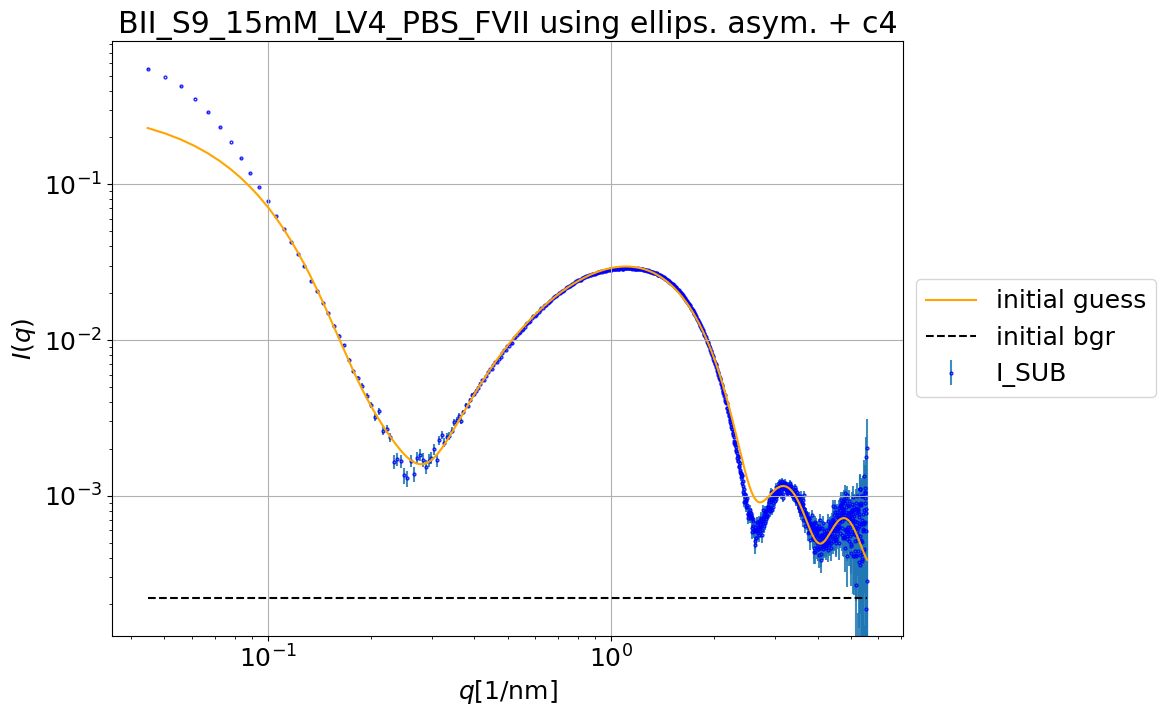

In [12]:
lower_bounds = [        9,        2,     0.8,         0,       0,      0,        0.2,      0.2,      0.5,      1.5,  -np.inf] # ,    0,    0,  -np.inf]
upper_bounds = [       25,        9,     1.5,       0.7,      10,     10,        0.5,      0.5,        1,        2,  +np.inf] # ,  0.2,  0.5,  +np.inf]
#======================== Fit ===========================================
# residuals = I - fit_function(q, *popt)
# chi2 = np.sum((residuals / I_err)**2) / (len(I) - len(p0) - 1)
# print(chi2)
# residuals = I - fit_function(q, *popt)
# chi2 = np.sum((residuals / I_err_op)**2) / (len(I) - len(p0) - 1)
# print("chi2 op. err. /30", chi2)
# residuals = I - fit_function(q, *popt)
# chi2 = np.sum((residuals / I_err_op20)**2) / (len(I) - len(p0) - 1)
# print("chi2 op. err. /20", chi2)
# popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=1000, p0=p0, bounds = (lower_bounds, upper_bounds))

# param_names = fit.param_names.get(param_set)

# perr = np.sqrt(np.diag(pcov))
# for name, value in zip(param_names, popt):
#     globals()[name] = value
# chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
# #=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), len(q_thinned))
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=2,markeredgewidth=1,markeredgecolor='Blue', markerfacecolor='None', alpha=0.85, ls="None", label='I_SUB', zorder=1)
# plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
# plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2_fit, c3_fit, c4_fit), color='black', label='pow law bgr')
plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, 0, 0, p0[-1]), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using ellips. asym. + c4')
plt.grid(True)
plt.legend()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
# legend.set_title(info_text_print)

plt.tight_layout()
# plt.savefig(target_folder / f"LV4_{fit_function.__name__}_FINAL_Jan31.png", bbox_inches='tight', pad_inches=0.05)
plt.show()
info_text="_"
#==================== EDP Plot ==================================================
# fig=fit.EDP_plot(R, sigma_h1_fit, sigma_h2_fit, sigma_c_fit, rho_h1_fit, rho_h2_fit, z_h_fit, z_h_fit, info_text, 
#              f'{BM29.sample_dict[sample]} using {fit_function.__name__}')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_FINAL.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

[17.48, 6.869, 1.703, 1.33, 0.1981, 0.4524, 0.814, 1.807, 0.0001049, 0.0008936]
R = 18 (17, 25)
sigma_R = 7 (2, 8)
rho_h1 = 1.8 (1.7, 3)
rho_h2 = 1.4 (0.8, 1.7)
sigma_h1 = 0.2 (0.13, 0.6)
sigma_h2 = 0.3 (0.13, 0.6)
sigma_c = 0.75 (0.5, 1.2)
z_h = 1.75 (1.5, 2)
scale = 0.00013965 (0, 1)
c4 = 0 (0, 1)
chi2_initial = 859.52
 
R_fit = 17.479 ± 0.18198
sigma_R_fit = 6.8688 ± 0.096852
rho_h1_fit = 1.7026 ± 0.36152
rho_h2_fit = 1.3301 ± 0.098634
sigma_h1_fit = 0.19806 ± 0.063068
sigma_h2_fit = 0.45244 ± 0.018849
sigma_c_fit = 0.81397 ± 0.089137
z_h_fit = 1.8066 ± 0.024184
scale_fit = 0.0001049 ± 6.0816e-06
c4_fit = 0.00089364 ± 1.4879e-05
chi2 = 11.893


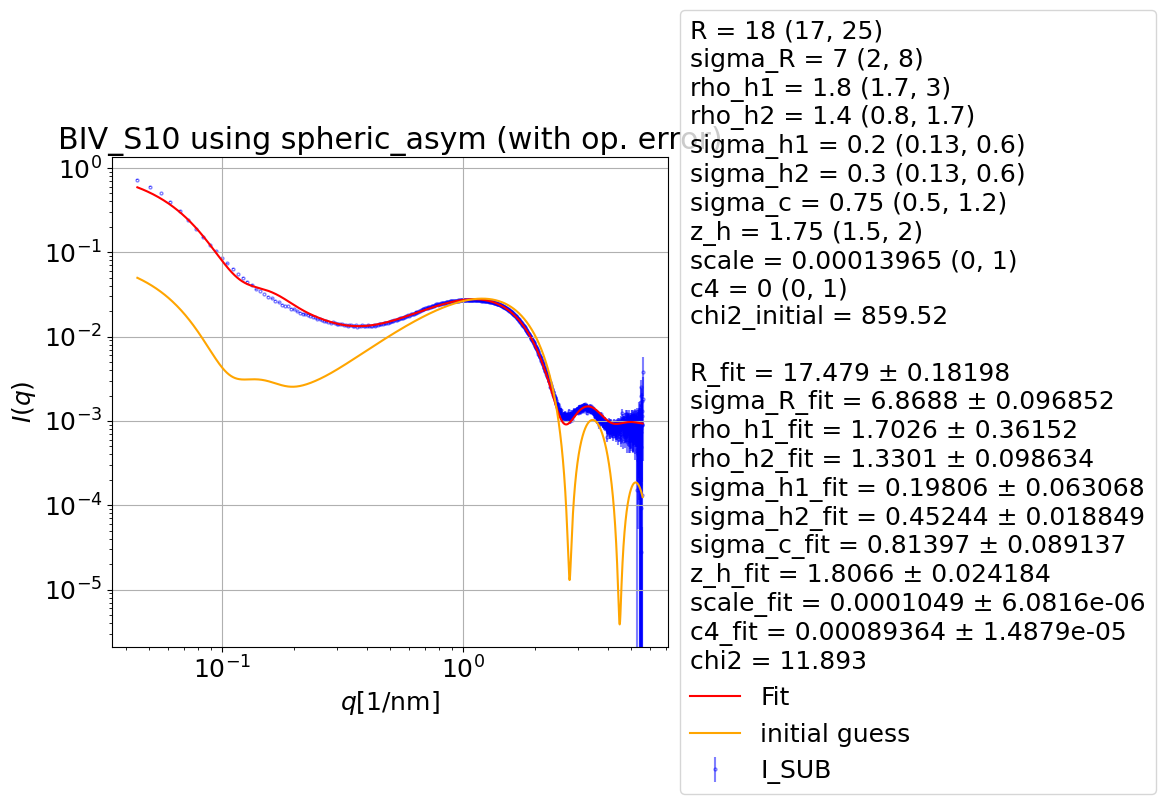

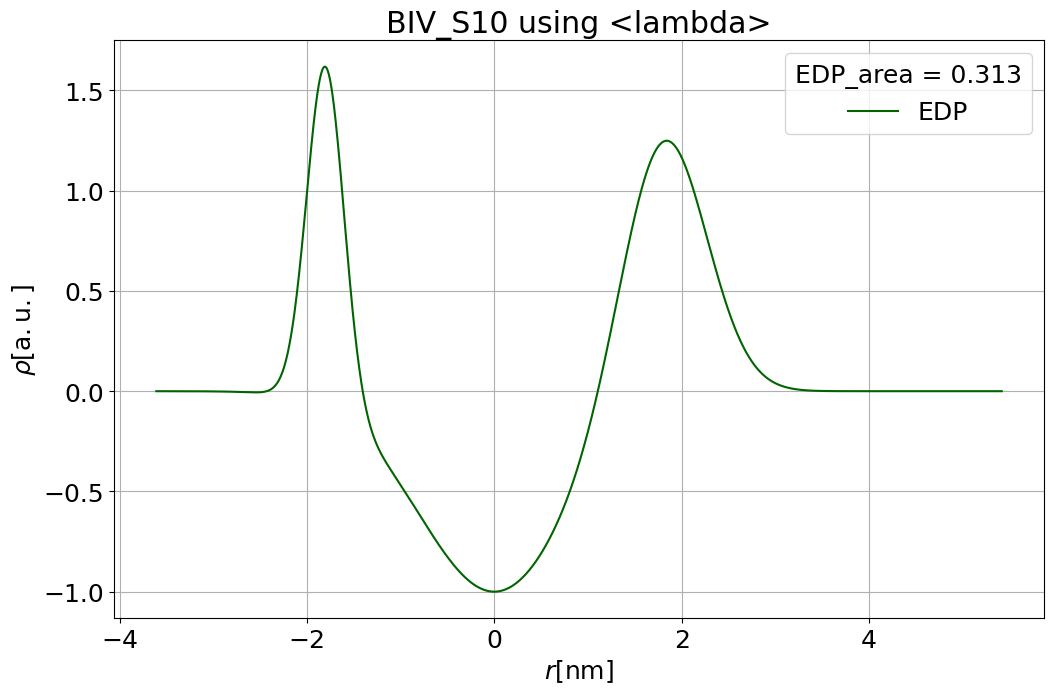

In [12]:
# SPHERIC ASYM + C4

sample = "BIV_S10" 
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
fit_function_name = "ULV_spheric_asym_C4"
q     = q
I     = I
I_err_Poisson = Ierr
I_err_op = BM29.op_error_classic(q, I)

# ========================== Parameters ==========================
R = 18
sigma_R = 7
rho_h1 = 1.8
rho_h2 = 1.4
sigma_h1 = 0.2
sigma_h2 = 0.3
sigma_c = 0.75
z_h = 1.75
scale = 0.00013965
c4 = 0

# ========================== Setting Bounds ==============================
p0           = [   R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,   c4] #,      c2,      c3,      c4]
lower_bounds = [  17,          2,      1.7,     0.8,        0.13,      0.13,      0.5,    1.5,      0,   0] #,       0,       0, -np.inf]
upper_bounds = [  25,          8,      3.0,      1.7,         0.6,       0.6,      1.2,      2,      1,   1] #,       4,     0.5, +np.inf]
# p0 = [13.84263741,  7.45905129,  1.01586004,  1.71244435, 0.49757307, 0.59267887, 0.52259504,  1.57056397,  0.12634116]
# p0 = [17, 3, 1.225, 2.5, 0.6374, 0.1734, 1.152, 1.787, 0.0001424]

#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err_Poisson, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = ["R_fit", "sigma_R_fit", "rho_h1_fit", "rho_h2_fit", "sigma_h1_fit", "sigma_h2_fit", "sigma_c_fit", "z_h_fit", "scale_fit", "c4_fit"]

perr = np.sqrt(np.diag(pcov))
fit_lib_entry = "["
for name, value in zip(param_names, popt):
    globals()[name] = value
    fit_lib_entry += f"{value:.4g}, "
fit_lib_entry = fit_lib_entry[:-2]
fit_lib_entry += "]"
print(fit_lib_entry)

chi2, info_text_print = fit.all_info(q, I, I_err_Poisson, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
print(info_text_print)

#=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), 10000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err_Poisson, marker="o", markersize=2,markeredgewidth=1,ecolor="Blue", markeredgecolor='Blue', markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{sample} using spheric_asym (with op. error)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{fit_function.__name__}_op_error2.png",dpi=400, bbox_inches='tight', pad_inches=0.05)
plt.show()

fig=fit.EDP_plot(R_fit, sigma_h1_fit, sigma_h2_fit, sigma_c_fit, rho_h1_fit, rho_h2_fit, z_h_fit, z_h_fit, info_text_print, 
             f'{sample} using {fit_function.__name__}')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error2.png", dpi=400, bbox_inches='tight', pad_inches=0.05)


Computing I(q): 100%|████████████████████████| 908/908 [00:02<00:00, 427.45it/s]


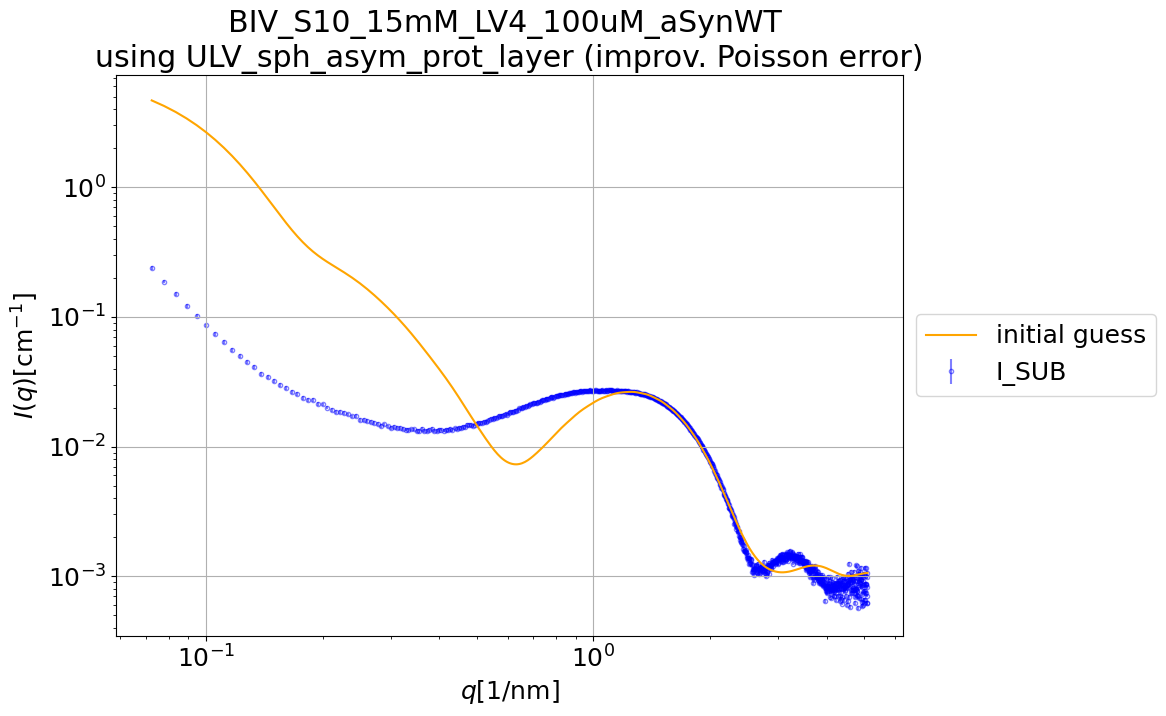

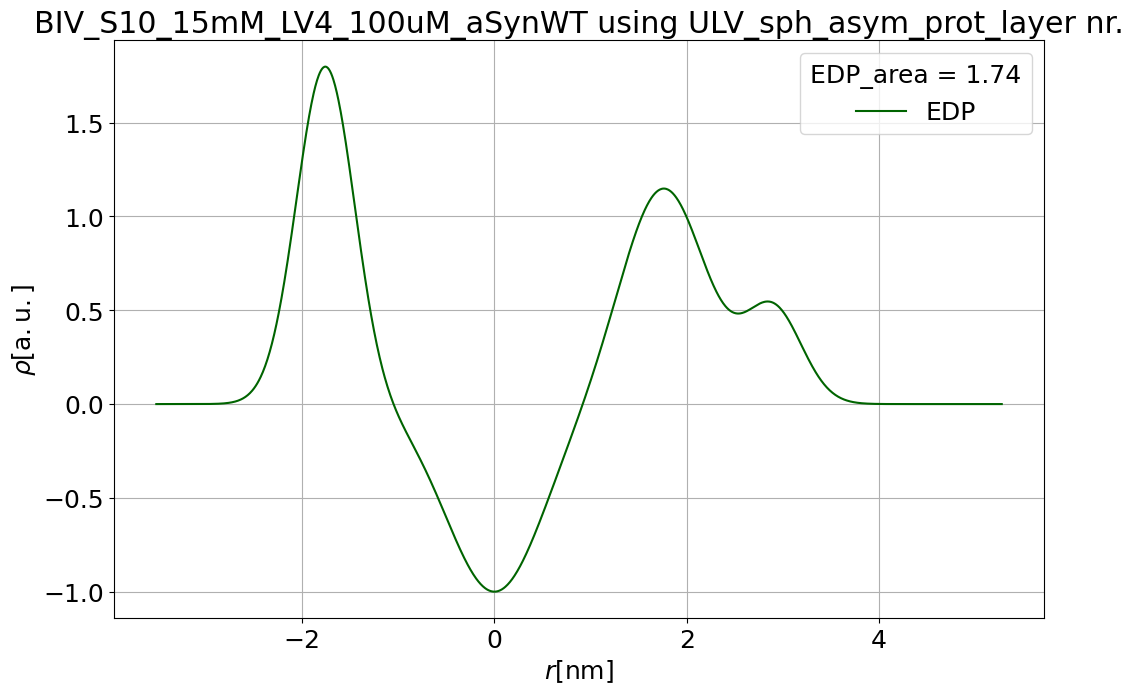

In [ ]:
# spheric asym + prot layer C4

sample = "BIV_S10" 
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
fit_function_name = "ULV_spheric_asym_C4"
mask = (q >= 0.07) & (q <= 5.1)
q    = q[mask]
I    = I[mask]
Ierr = BM29.op_error_classic(q, I)

fit_function_name = "ULV_sph_asym_prot_layer"
fit_function = lambda q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale, c4: fit.ULV_sph_asym_prot_layer(q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale, 0, 0, c4)

# ========================== Parameters ==========================
R = 10
sigma_R = 5.5  # BEST FROM SPHERICAL ASYM FIT
rho_h1 = 1.8
rho_h2 = 1.15
sigma_h1 = 0.3
sigma_h2 = 0.44
sigma_c = 0.5
z_h = 1.76
z_h3 = 2.9
sigma_h3 = 0.3
rho_h3 = 0.5
scale = 5e-7
c4 = 1e-3
# ========================== Setting Bounds ==============================
p0           = [        R,  sigma_R,       rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,  z_h3, sigma_h3,   rho_h3,    scale, c4] # ,   c2,   c3,       c4]
lower_bounds = [       14,        7,          0.8,    1.0,        0.4,      0.1,      0.7,      1.7,     3,      0.7,      0.0,        0] #,    0,    0,  -np.inf]
upper_bounds = [       15,        8,          1.0,    2.5,        0.6,      0.3,      1.2,      1.9,     5,      1.2,      2.0,   0.0001] # ,  0.2,  0.5,  +np.inf]


plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, Ierr, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
# plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q, fit_function(q, *p0), color='orange', label='initial guess')

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q) [\\mathrm{cm}^{-1}]$')
plt.title(f'{BM29.sample_dict[sample]} \nusing {fit_function_name} (improv. Poisson error)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
# legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{sample}_{fit_function_name}_IRP{i}_{DAY}.png",dpi=400, bbox_inches='tight', pad_inches=0.05)

fig=fit.EDP_plot(R, sigma_h1, sigma_h2, sigma_c, rho_h1, rho_h2, z_h, z_h, "",  f'{BM29.sample_dict[sample]} using {fit_function_name} nr.', z_h3, sigma_h3, rho_h3)
# fig=fit.EDP_plot(R_fit, sigma_h1_fit, sigma_h2_fit, sigma_c_fit, rho_h1_fit, rho_h2_fit, z_h_fit, z_h_fit, "",  f'{BM29.sample_dict[sample]} using {fit_function_name} nr', z_h3_fit, sigma_h3_fit, rho_h3_fit)
# fig.savefig(target_folder / f"EDP_{sample}_{fit_function_name}_IRP{i}.png", dpi=400, bbox_inches='tight', pad_inches=0.05)


Computing I(q): 100%|██████████████████████| 1000/1000 [00:01<00:00, 666.57it/s]


[13.57, 0.3291, 1.564, 0.8525, 0.3012, 0.6, 0.8701, 1.777, 4.043e-07, 0.0005774]


Computing I(q): 100%|██████████████████████| 1000/1000 [00:01<00:00, 756.88it/s]


R = 17 (7, 25)
sigma_R = 0.17 (0, 1)
rho_h1 = 1.8 (0.8, 3)
rho_h2 = 1.4 (0.8, 1.7)
sigma_h1 = 0.2 (0.13, 0.6)
sigma_h2 = 0.3 (0.13, 0.6)
sigma_c = 0.75 (0.5, 1.2)
z_h = 1.75 (1.5, 2)
scale = 1e-06 (0, 1)
c4 = 0 (0, 1)
chi2_initial = 25204
 
R_fit = 13.573 ± 0.25274
sigma_R_fit = 0.3291 ± 0.011791
rho_h1_fit = 1.5637 ± 0.64077
rho_h2_fit = 0.85246 ± 0.60128
sigma_h1_fit = 0.30119 ± 0.34837
sigma_h2_fit = 0.6 ± 0.031914
sigma_c_fit = 0.87009 ± 0.72482
z_h_fit = 1.7769 ± 0.19337
scale_fit = 4.0428e-07 ± 8.9459e-08
c4_fit = 0.00057743 ± 0.00016459
chi2 = 7.5772


Computing I(q): 100%|███████████████████| 10000/10000 [00:02<00:00, 4570.77it/s]


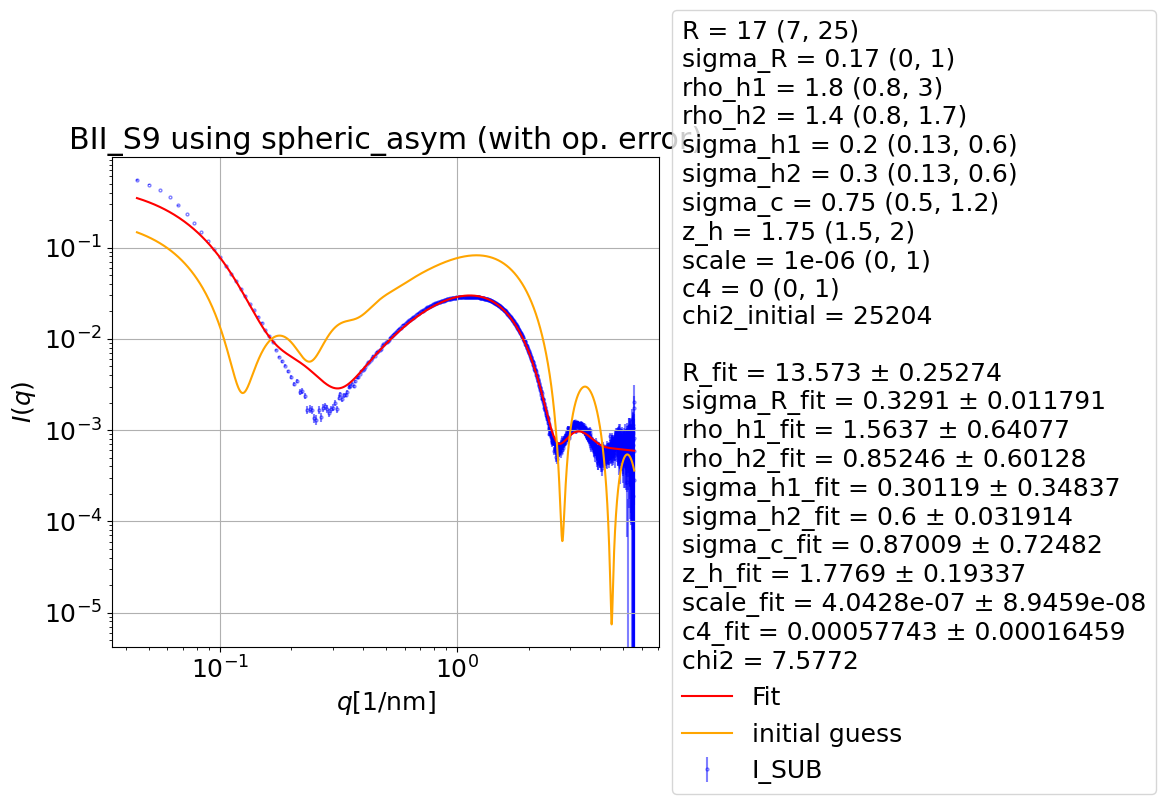

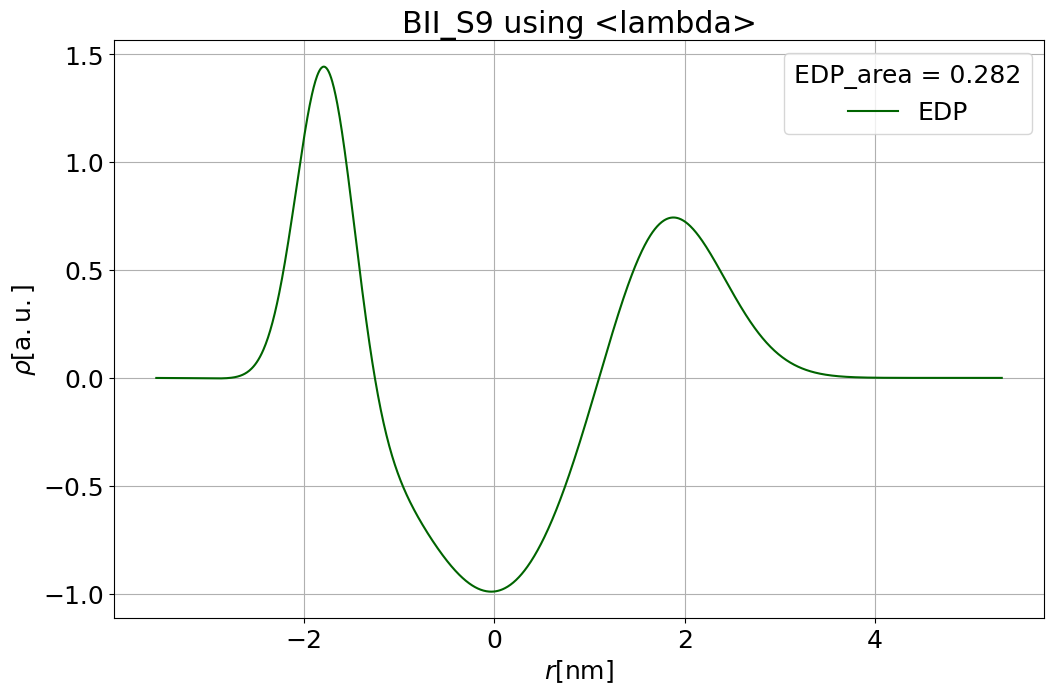

np.float64(0.9999986466588928)

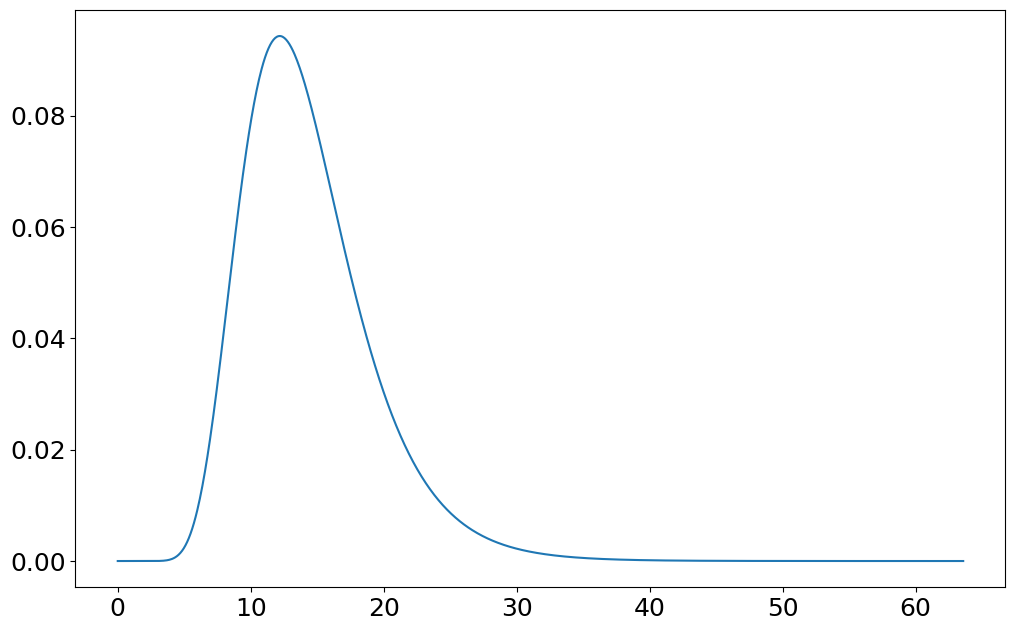

In [6]:
# SPHERIC ASYM LOG NORMAL + C4
sample = "BII_S9" 
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym_lognormal(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
fit_function_name = "ULV_spheric_asym_C4_lognormal"
q     = q
I     = I
I_err_Poisson = Ierr
I_err_op = BM29.Poisson_error_lowq_highq(q, I_err_Poisson)

# ========================== Parameters ==========================
R = 17
sigma_R = 0.17
rho_h1 = 1.8
rho_h2 = 1.4
sigma_h1 = 0.2
sigma_h2 = 0.3
sigma_c = 0.75
z_h = 1.75
scale = 1e-6
c4 = 0

# ========================== Setting Bounds ==============================
p0           = [   R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,   c4] #,      c2,      c3,      c4]
lower_bounds = [   7,          0,      0.8,      0.8,        0.13,      0.13,      0.5,    1.5,      0,   0] #,       0,       0, -np.inf]
upper_bounds = [  25,          1,      3.0,      1.7,         0.6,       0.6,      1.2,      2,      1,   1] #,       4,     0.5, +np.inf]
# p0 = [13.84263741,  7.45905129,  1.01586004,  1.71244435, 0.49757307, 0.59267887, 0.52259504,  1.57056397,  0.12634116]
# p0 = [17, 3, 1.225, 2.5, 0.6374, 0.1734, 1.152, 1.787, 0.0001424]
# p0 = [9.25, 0.4552, 1.261, 1.071, 0.3214, 0.3518, 0.6763, 1.906, 7.089e-07, 0.0005629]
#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err_op, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = ["R_fit", "sigma_R_fit", "rho_h1_fit", "rho_h2_fit", "sigma_h1_fit", "sigma_h2_fit", "sigma_c_fit", "z_h_fit", "scale_fit", "c4_fit"]

perr = np.sqrt(np.diag(pcov))
fit_lib_entry = "["
for name, value in zip(param_names, popt):
    globals()[name] = value
    fit_lib_entry += f"{value:.4g}, "
fit_lib_entry = fit_lib_entry[:-2]
fit_lib_entry += "]"
print(fit_lib_entry)

chi2, info_text_print = fit.all_info(q, I, I_err_op, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
print(info_text_print)

#=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), 10000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err_Poisson, marker="o", markersize=2,markeredgewidth=1,ecolor="Blue", markeredgecolor='Blue', markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{sample} using spheric_asym (with op. error)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{fit_function.__name__}_op_error2.png",dpi=400, bbox_inches='tight', pad_inches=0.05)
plt.show()

fig=fit.EDP_plot(R_fit, sigma_h1_fit, sigma_h2_fit, sigma_c_fit, rho_h1_fit, rho_h2_fit, z_h_fit, z_h_fit, info_text_print, 
             f'{sample} using {fit_function.__name__}')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error2.png", dpi=400, bbox_inches='tight', pad_inches=0.05)
plt.show()

f = plt.figure(figsize=(12, 7.5))
from scipy.stats import lognorm
sigma = sigma_R_fit
R0 = R_fit
R = np.linspace(0, R_fit + 50, 1000)
P = lognorm.pdf(R, s=sigma, scale=R0)
plt.plot(R, P)
np.trapezoid(P, R)
